<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/06_Android_Malware_Detection/HybridQCNN_AndroidMalwareImages_Ciaramella2022.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid quantum CNN for malware-image classification: Ciaramella et al. (2022) step by step

This notebook re-implements, runs and checks the method of

> Giovanni Ciaramella, Giacomo Iadarola, Fabio Martinelli, Francesco Mercaldo, Antonella Santone and Marco Storto,
> "Introducing Quantum Computing in Mobile Malware Detection", *17th International Conference on Availability, Reliability
> and Security (ARES 2022)*, Vienna, 23-26 August 2022. https://doi.org/10.1145/3538969.3543816

The authors publish no code and no data. The paper converts the executable code of 8,446 Android apps (six malware families
plus legitimate "Trusted" apps) into grey-scale images, trains four classical image classifiers (LeNet, AlexNet, a
"Standard CNN", VGG16) and a **Hybrid quantum CNN** whose first layer is a quantum convolution built with TensorFlow Quantum, and
compares them.

**What the notebook does.** (1) Downloads a public image-based malware set, converts it to the paper's input format
(grey-scale squares of 100x100 and 25x25 pixels). (2) Rebuilds the quantum convolution ("quanvolution") layer in **PennyLane**
(TensorFlow Quantum cannot be installed in Colab any more): every 2x2 patch of the image is loaded into 4 qubits, passed through a
fixed random quantum circuit, and read out as 4 expectation values; two such circuits give the 8 channels of the paper's `QConv(filter_size=2, depth=8)`.
(3) Trains the paper's five networks in **PyTorch** with the layer lists printed in the paper (Listings 1 and 2) and the epoch/batch settings of its
Table 1. (4) Adds two controls that isolate the quantum layer (a trainable and a frozen *classical* 2x2 convolution in the same slot) and
two shallow baselines (random forest, RBF-SVM) on the identical pixels. (5) Prints the paper's Table 2 next to ours with a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a **CPU** runtime, *Runtime -> Run all*. The first cell installs pinned
packages; if Colab asks you to restart the session, do so and run all again. No GPU and no quantum-hardware account is needed.
The first run downloads about 240 MB of images (cached afterwards) and the 528 MB ImageNet weights of VGG16.

**Important caveat, read first.** The authors' 8,446 Android images are not public. The closest public substitute with the
same construction (bytes of an executable written as a grey-scale image, classified by malware family) is **Malimg**
(25 *Windows* malware families, Nataraj et al. 2011). The absolute numbers below therefore belong to a different, much easier
data set with a different class mix and a much smaller sample; the notebook compares *architectures*, not the paper's exact accuracies.

**Runtime.** `FAST_MODE = True`: about 5 minutes on a laptop CPU (60 images per class, 1 split, shortened epochs).
`FAST_MODE = False`: the paper's epochs (50/50/25/25/20), up to 160 images per class, 3 random splits; see the timing printed at the end.

## The paper in one page

**Problem.** Assign an Android application to a malware family, or to "Trusted" (legitimate), from a picture of its code.

**Decision.** 7-class classification (Airpush, Dowgin, FakeInst, Fusob, Jisut, Mecor, Trusted).

**Data.** 8,446 apps: Airpush 1,170, Dowgin 763, FakeInst 2,129, Fusob 1,275, Jisut 550, Mecor 1,499, Trusted 1,060. Malware labels were
checked with VirusTotal. Split 80/20 into training and test set. The executable code is written as a PNG grey-scale image
(Section 2.1: bytes -> unsigned integers -> 2-D matrix -> pixels).

**Models and settings (Table 1).**

| Model | Image | Batch | Epochs | Training time |
|---|---|---|---|---|
| LeNet | 100x1 | 32 | 50 | 2 min 47 s |
| AlexNet | 100x1 | 32 | 50 | 3 min 59 s |
| Standard CNN (Listing 1) | 100x1 | 32 | 25 | 2 min 49 s |
| VGG16 (ImageNet convolutional weights kept, dense head trained) | 100x3 | 32 | 25 | 5 min 56 s |
| Hybrid-QCNN (Listing 2) | 25x1 | 32 | 20 | 7 h 43 min |

**Hybrid-QCNN (Listing 2).** `QConv(filter_size=2, depth=8, relu)` -> `Conv2D(16, 2x2, relu)` -> `Flatten` -> `Dense(32, relu)` -> `Dense(7, softmax)`;
the quantum layer is simulated with TensorFlow Quantum.

**Claims (Table 2, test set).**

| Model | Loss | Accuracy | Precision | Recall | F-measure | AUC |
|---|---|---|---|---|---|---|
| LeNet | 1.86 | 0.25 | 0 | 0 | 0 | 0.62 |
| AlexNet | 1.87 | 0.25 | 0 | 0 | 0 | 0.62 |
| Standard CNN | 0.28 | 0.90 | 0.95 | 0.84 | 0.89 | 0.99 |
| VGG16 | 0.15 | 0.95 | 0.96 | 0.95 | 0.95 | 0.99 |
| Hybrid-QCNN | 0.81 | 0.91 | 0.92 | 0.91 | 0.91 | 0.97 |

Further claims: VGG16 is best; Hybrid-QCNN is second although fed 25x25 instead of 100x100x3 pixels; the Hybrid-QCNN takes about 8 h against 6 min for
VGG16; its errors concentrate on Airpush/Dowgin samples that look like Trusted ones (Figs. 4-5, Table 3).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | 8,446 Android apps converted to images, not public | **Malimg** (Windows byte-plots, public mirror on Hugging Face `yanjunxi/Malimg`), 7 families, at most 160 images per family |
| Number of classes | 7 (6 families + Trusted) | 7 (Allaple.A, Allaple.L, Yuner.A, Instantaccess, VB.AT, Fakerean, Lolyda.AA1); Malimg has no benign class |
| Sample size | 8,446 | at most 769 (val+test splits of the mirror pooled); `FAST_MODE`: 60 per family |
| Split | 80/20 train/test, "balanced" | stratified 80/20, re-drawn for each of 3 seeds (1 in FAST) |
| Image size | 100x100 (LeNet, AlexNet, CNN), 100x100x3 (VGG16), 25x25 (Hybrid) | same; images resized with box averaging; VGG16 gets the grey channel replicated 3x |
| Quantum layer | `QConv(filter_size=2, depth=8)` in TensorFlow Quantum, circuit and stride not given | PennyLane `default.qubit`; 2x2 patch -> 4 qubits, `RY(pi x)` encoding, fixed `RandomLayers` circuit, `<Z>` on each qubit; two circuits give 8 channels; stride 2; `# CHOICE` |
| Is the quantum layer trained? | not stated | fixed (not trained), as in the usual TFQ "quanvolution" recipe; features computed once; `# CHOICE` |
| Listing 2 size vs text | Listing: `NEW_SIZE = 10`; text and Table 1: 25x25 | 25x25 (`IMG_Q`), the value used in Table 1 and the conclusion |
| Optimiser, learning rate, loss | not given | Adam, lr 1e-3, cross-entropy; `# CHOICE` |
| Framework | TensorFlow / Keras | PyTorch (layer lists follow Listing 1 and 2); `# CHOICE` |
| LeNet / AlexNet layers | "2 conv + 2 pool + 2 FC", "3 conv + 2 FC", no sizes | classic LeNet-5 and a small 3-conv AlexNet-style net; `# CHOICE` |
| VGG16 head | "2 fully connected layers and softmax" | frozen ImageNet convolutional part, `Dense(256) -> Dropout(0.5) -> Dense(7)`; `# CHOICE` |
| Precision/recall/F | multi-class, averaging not stated | macro average (also weighted shown); AUC one-vs-rest macro |
| Seeds, repeats | one run | `SEED = 42`, mean +- std over splits |
| Hardware times | GPU/TFQ, 7 h 43 min | CPU; our quantum layer is pre-computed, so the 8-hour cost is **not** reproduced |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and torch/torchvision.
# The pip line runs on Colab (or wherever pennylane is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1" "pennylane-lightning==0.45.0"
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install.")
if importlib.util.find_spec("torchvision") is None:
    %pip install -q torch torchvision --index-url https://download.pytorch.org/whl/cpu

pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE   = False      # True: class demo in about 5 minutes. False: the paper's epochs, 3 splits (about 55 min on a shared 8-thread CPU).
SEED        = 42        # CHOICE: the paper gives no seed
IBM_TOKEN   = ""        # not used: everything runs on the exact PennyLane simulator

# Data -------------------------------------------------------------------------------------------------------------
# CHOICE: Malimg families used as a stand-in for the paper's 6 Android families + Trusted (7 classes)
CLASSES        = ["Allaple.A", "Allaple.L", "Yuner.A", "Instantaccess", "VB.AT", "Fakerean", "Lolyda.AA1"]
CAP_PER_CLASS  = 60 if FAST_MODE else 160     # images per family (the smaller families have only 43-87 images in the mirror)
TEST_SIZE      = 0.2                          # paper: 80 / 20
N_SEEDS        = 1 if FAST_MODE else 3        # independent stratified splits (mean +- std)
IMG_CLASSIC    = 100                          # paper Table 1: 100x100 for LeNet, AlexNet, Standard CNN, VGG16
IMG_Q          = 25                           # paper Table 1 / conclusion: 25x25 for the Hybrid-QCNN
USE_TRAIN_ZIP  = False                        # True: also download the 936 MB train.zip (about 6,000 more images; then raise CAP_PER_CLASS)
DATA_DIR       = "data"                       # cache folder; to use your own copy put val.zip / test.zip (and train.zip) here
HF_REPO        = "yanjunxi/Malimg"

# Training (Table 1 of the paper) ------------------------------------------------------------------------------------
BATCH          = 32
LR             = 1e-3                         # CHOICE: not given
PAPER_EPOCHS   = {"LeNet": 50, "AlexNet": 50, "Standard CNN": 25, "VGG16": 25, "Hybrid-QCNN": 20}
if FAST_MODE:   # shortened budgets for the class demo
    EPOCHS = {"LeNet": 15, "AlexNet": 15, "Standard CNN": 8, "VGG16": 8, "Hybrid-QCNN": 8}
else:
    EPOCHS = dict(PAPER_EPOCHS)

# Quanvolution layer -----------------------------------------------------------------------------------------------
Q_FILTER       = 2                            # paper: filter_size=2  -> 2x2 patch -> 4 qubits
Q_STRIDE       = 2                            # CHOICE: not given
N_Q_CIRCUITS   = 2                            # CHOICE: 2 circuits x 4 qubit read-outs = 8 channels = paper's depth=8
Q_LAYERS       = 4                            # CHOICE: layers of the random circuit
N_THREADS      = 4

In [3]:
import os, io, time, zipfile, warnings, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from PIL import Image

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 120); pd.set_option("display.max_columns", 30)

import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import pennylane as qml
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             log_loss, confusion_matrix)

torch.set_num_threads(N_THREADS)
torch.manual_seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
N_CLASSES = len(CLASSES)

print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| pennylane", qml.__version__)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| EPOCHS =", EPOCHS, "| N_SEEDS =", N_SEEDS, "| CAP_PER_CLASS =", CAP_PER_CLASS)
T_NOTEBOOK_START = time.time()

torch 2.14.1+cpu | torchvision 0.29.1+cpu | pennylane 0.45.1
numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE = False | EPOCHS = {'LeNet': 50, 'AlexNet': 50, 'Standard CNN': 25, 'VGG16': 25, 'Hybrid-QCNN': 20} | N_SEEDS = 3 | CAP_PER_CLASS = 160


## 1. The data: executables drawn as grey-scale pictures

The paper's idea (Section 2.1) is to read a program file as a long list of bytes, cut the list into rows and show each byte (0 to 255) as a
grey pixel. Variants of one malware family share code, so their pictures share textures; a convolutional network can learn those textures.
The authors did this for the `classes.dex` code of Android apps. Those 8,446 pictures are not published, and building them needs
the malicious APKs themselves (AndroZoo / AMD access requires registration and a licence), which a notebook cannot fetch on its own.

**Public substitute: Malimg** (Nataraj et al., 2011). Same construction (bytes -> grey-scale image), classified by malware family, but built
from Windows PE files. We use a public Hugging Face mirror (`yanjunxi/Malimg`) and pool its small `val.zip` and `test.zip` (about 240 MB,
923 + 957 images over 25 families) instead of the 936 MB `train.zip`. Seven families with enough images stand in for the paper's seven classes.
Images have a width fixed by file size and a variable height; as in the paper they are resized to squares.

In [4]:
def fetch(name):
    """Return the local path of a file of the Malimg mirror; download it once into DATA_DIR."""
    path = os.path.join(DATA_DIR, name)
    if os.path.exists(path) and os.path.getsize(path) > 1_000_000:
        return path
    url = f"https://huggingface.co/datasets/{HF_REPO}/resolve/main/{name}"
    print("downloading", url)
    try:
        with requests.get(url, stream=True, timeout=60) as r:
            r.raise_for_status()
            with open(path + ".part", "wb") as f:
                for chunk in r.iter_content(1 << 20):
                    f.write(chunk)
        os.replace(path + ".part", path)
    except Exception as e:                        # fallback: huggingface_hub
        print("direct download failed (", e, ") -> trying huggingface_hub")
        from huggingface_hub import hf_hub_download
        path = hf_hub_download(HF_REPO, name, repo_type="dataset", local_dir=DATA_DIR)
    return path

zip_names = ["val.zip", "test.zip"] + (["train.zip"] if USE_TRAIN_ZIP else [])
members = {c: [] for c in CLASSES}                # class -> list of (zip path, member name)
for zn in zip_names:
    zp = fetch(zn)
    with zipfile.ZipFile(zp) as z:
        for n in z.namelist():
            if n.endswith(".png"):
                cls = n.split("/")[-2]
                if cls in members:
                    members[cls].append((zp, n))
print({c: len(v) for c, v in members.items()})

{'Allaple.A': 590, 'Allaple.L': 319, 'Yuner.A': 160, 'Instantaccess': 87, 'VB.AT': 82, 'Fakerean': 77, 'Lolyda.AA1': 43}


In [5]:
# CHOICE: cap the number of images per family (seeded draw) so that the quantum simulation stays small.
t0 = time.time()
sel = []
for ci, c in enumerate(CLASSES):
    items = sorted(members[c])
    take = rng.permutation(len(items))[:CAP_PER_CLASS]
    sel += [(items[i], ci) for i in sorted(take)]

def load_square(img, size):
    return np.asarray(img.resize((size, size), Image.Resampling.BOX), dtype=np.uint8)

X100, X25, y = [], [], []
open_zips = {}
for (zp, n), ci in sel:
    z = open_zips.setdefault(zp, zipfile.ZipFile(zp))
    im = Image.open(io.BytesIO(z.read(n))).convert("L")
    X100.append(load_square(im, IMG_CLASSIC)); X25.append(load_square(im, IMG_Q)); y.append(ci)
for z in open_zips.values(): z.close()
X100 = np.stack(X100); X25 = np.stack(X25); y = np.array(y)
print(f"{len(y)} images in {time.time()-t0:.0f} s | X100 {X100.shape} | X25 {X25.shape}")
print(pd.Series(np.bincount(y, minlength=N_CLASSES), index=CLASSES, name="images per family").to_frame().T)

769 images in 12 s | X100 (769, 100, 100) | X25 (769, 25, 25)
                   Allaple.A  Allaple.L  Yuner.A  Instantaccess  VB.AT  Fakerean  Lolyda.AA1
images per family        160        160      160             87     82        77          43


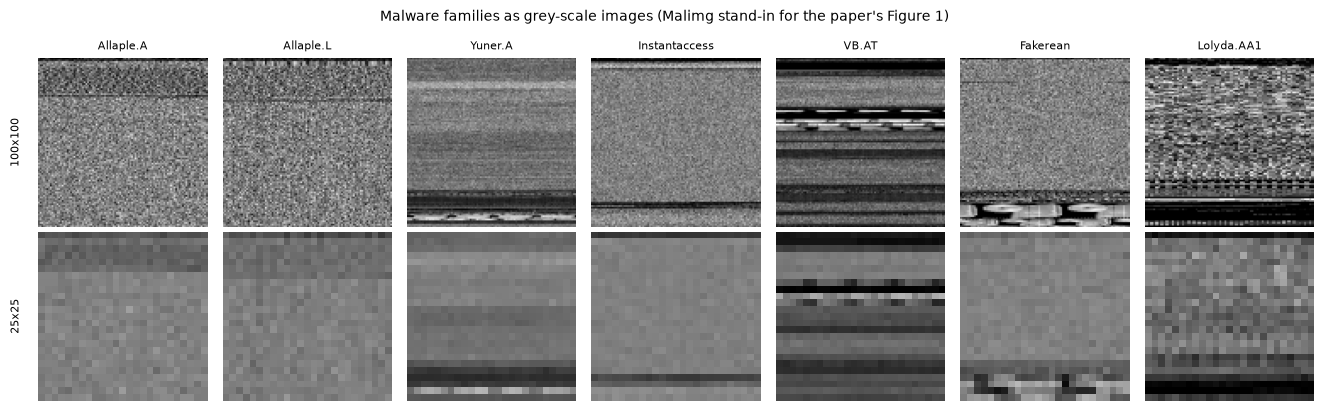

In [6]:
# Counterpart of Figure 1: two samples of two different families (here a few more), at the paper's two resolutions.
fig, axes = plt.subplots(2, N_CLASSES, figsize=(1.9 * N_CLASSES, 4.2))
for ci, c in enumerate(CLASSES):
    k = np.where(y == ci)[0][0]
    axes[0, ci].imshow(X100[k], cmap="gray", vmin=0, vmax=255); axes[0, ci].set_title(c, fontsize=8)
    axes[1, ci].imshow(X25[k], cmap="gray", vmin=0, vmax=255)
    for r in (0, 1): axes[r, ci].axis("off")
axes[0, 0].text(-0.1, 0.5, "100x100", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right", fontsize=8)
axes[1, 0].text(-0.1, 0.5, "25x25", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right", fontsize=8)
plt.suptitle("Malware families as grey-scale images (Malimg stand-in for the paper's Figure 1)", fontsize=10)
plt.tight_layout(); plt.show()

## 2. The quantum convolution ("quanvolution") layer in PennyLane

A classical convolution slides a small filter over the image and, at each position, computes one number from the 2x2 patch of pixels beneath it. The
quantum version replaces that arithmetic by a **small quantum circuit**:

1. **Encode** the four pixels of the patch (scaled to [0, 1]) as rotation angles `RY(pi * pixel)` on four qubits.
2. Apply a **fixed random circuit** (`qml.RandomLayers`: random rotations and CNOTs; the circuit is drawn once from a seed and never changed). It entangles the four qubits.
3. **Measure** the expectation value of Pauli-Z on each qubit: four numbers in [-1, 1] per patch, i.e. four output channels.

The paper's layer is called `QConv(filter_size=2, depth=8)`, so we use two different random circuits (4 read-outs each) to obtain 8 channels. Because the
circuit is fixed, the layer is a *feature extractor*: we can run it once for every image and cache the result, and the network that follows
(`Conv2D(16, 2x2)`, `Dense(32)`, `Dense(7)`) is what gets trained. That is the standard recipe of the TensorFlow Quantum quanvolution tutorial, which we assume
the authors followed; the paper does not say whether the circuit parameters are trained (`# CHOICE`).

PennyLane's parameter broadcasting lets us evaluate thousands of patches in one call on the exact state-vector simulator.

In [7]:
dev = qml.device("default.qubit", wires=Q_FILTER * Q_FILTER)
NQ = Q_FILTER * Q_FILTER
q_rng = np.random.default_rng(SEED)
# CHOICE: random circuit parameters and gate pattern are drawn once from SEED and then frozen
Q_WEIGHTS = [q_rng.uniform(0, 2 * np.pi, size=(Q_LAYERS, NQ)) for _ in range(N_Q_CIRCUITS)]
Q_SEEDS = [int(s) for s in q_rng.integers(0, 10_000, size=N_Q_CIRCUITS)]

def make_circuit(weights, gate_seed):
    @qml.qnode(dev)
    def circuit(patch):                                   # patch: (batch, 4), values in [0, 1]
        for j in range(NQ):
            qml.RY(np.pi * patch[..., j], wires=j)
        qml.RandomLayers(weights, wires=range(NQ), seed=gate_seed)
        return [qml.expval(qml.PauliZ(j)) for j in range(NQ)]
    return circuit

CIRCUITS = [make_circuit(w, s) for w, s in zip(Q_WEIGHTS, Q_SEEDS)]
print(qml.draw(CIRCUITS[0], max_length=110)(np.zeros((1, NQ))).split("\n\n")[0])

def quanvolve(images_u8, chunk=40_000):
    """images_u8: (N, S, S) uint8 -> (N, 8, S//2, S//2) float32 quantum feature maps (stride Q_STRIDE, patch Q_FILTER)."""
    N, S, _ = images_u8.shape
    out_s = (S - Q_FILTER) // Q_STRIDE + 1
    x = images_u8[:, : (out_s - 1) * Q_STRIDE + Q_FILTER, : (out_s - 1) * Q_STRIDE + Q_FILTER].astype(np.float64) / 255.0
    patches = np.stack([x[:, i * Q_STRIDE: i * Q_STRIDE + Q_FILTER, j * Q_STRIDE: j * Q_STRIDE + Q_FILTER].reshape(N, -1)
                        for i in range(out_s) for j in range(out_s)], axis=1)          # (N, out_s*out_s, 4)
    flat = patches.reshape(-1, NQ)
    chans = []
    for circ in CIRCUITS:
        res = np.concatenate([np.stack(circ(flat[s:s + chunk]), axis=-1) for s in range(0, len(flat), chunk)])   # (P, 4)
        chans.append(res)
    feats = np.concatenate(chans, axis=-1)                                              # (P, 8)
    return feats.reshape(N, out_s, out_s, -1).transpose(0, 3, 1, 2).astype(np.float32)

t0 = time.time()
XQ = quanvolve(X25)
T_QUANV = time.time() - t0
print(f"quantum feature maps {XQ.shape} in {T_QUANV:.1f} s  ({XQ.shape[0] * XQ.shape[2] * XQ.shape[3] * N_Q_CIRCUITS:,} circuit evaluations)")

0: ──RY(M0)─╭RandomLayers(M1)─┤  <Z>
1: ──RY(M0)─├RandomLayers(M1)─┤  <Z>
2: ──RY(M0)─├RandomLayers(M1)─┤  <Z>
3: ──RY(M0)─╰RandomLayers(M1)─┤  <Z>


quantum feature maps (769, 8, 12, 12) in 7.5 s  (221,472 circuit evaluations)


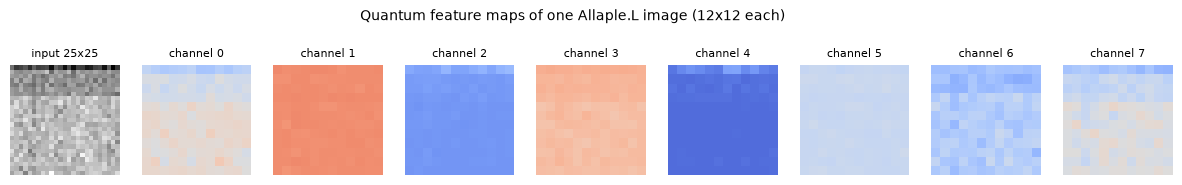

In [8]:
# What does the layer produce? One image, its 8 quantum channels.
k = np.where(y == 1)[0][0]
fig, axes = plt.subplots(1, 9, figsize=(15, 2.0))
axes[0].imshow(X25[k], cmap="gray"); axes[0].set_title("input 25x25", fontsize=8)
for c in range(8):
    axes[c + 1].imshow(XQ[k, c], cmap="coolwarm", vmin=-1, vmax=1); axes[c + 1].set_title(f"channel {c}", fontsize=8)
for a in axes: a.axis("off")
plt.suptitle(f"Quantum feature maps of one {CLASSES[1]} image (12x12 each)", fontsize=10, y=1.05); plt.show()

## 3. The networks of the paper

All five networks follow the paper's lists as far as the text goes. The two that the paper prints (Listing 1, Listing 2) are copied layer by layer; LeNet and AlexNet
are only described in words, so we use the classic LeNet-5 and a small three-convolution AlexNet-style net (`# CHOICE`). Training is Adam with learning rate
1e-3, batch 32, cross-entropy, for the epoch counts of Table 1.

Two controls are added to find out what the quantum layer itself contributes:

* **Classical conv front**: the same network as the Hybrid-QCNN, but `QConv` is replaced by a *trainable* `Conv2d(1, 8, 2, stride 2)`.
* **Frozen random conv front**: the same, but the 2x2 filters are random and not trained (a classical analogue of the fixed random quantum circuit).

In [9]:
class LeNet(nn.Module):                     # CHOICE: LeNet-5 layout for 100x100x1 input (the paper gives no sizes)
    def __init__(s, n):
        super().__init__()
        s.f = nn.Sequential(nn.Conv2d(1, 6, 5), nn.Tanh(), nn.AvgPool2d(2), nn.Conv2d(6, 16, 5), nn.Tanh(), nn.AvgPool2d(2), nn.Flatten())
        s.c = nn.Sequential(nn.Linear(16 * 22 * 22, 120), nn.Tanh(), nn.Linear(120, 84), nn.Tanh(), nn.Linear(84, n))
    def forward(s, x): return s.c(s.f(x))

class AlexNetSmall(nn.Module):              # CHOICE: "three convolution layers and two fully connected layers"
    def __init__(s, n):
        super().__init__()
        s.f = nn.Sequential(nn.Conv2d(1, 32, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2),
                            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                            nn.Conv2d(64, 96, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten())
        s.c = nn.Sequential(nn.Dropout(0.5), nn.Linear(96 * 12 * 12, 256), nn.ReLU(), nn.Dropout(0.5), nn.Linear(256, n))
    def forward(s, x): return s.c(s.f(x))

class StandardCNN(nn.Module):               # Listing 1 of the paper, layer by layer
    def __init__(s, n):
        super().__init__()
        s.net = nn.Sequential(nn.Conv2d(1, 30, 3), nn.ReLU(), nn.MaxPool2d(2),
                              nn.Conv2d(30, 15, 3), nn.ReLU(), nn.MaxPool2d(2),
                              nn.Dropout(0.25), nn.Flatten(),
                              nn.Linear(15 * 23 * 23, 128), nn.ReLU(), nn.Dropout(0.5),
                              nn.Linear(128, 50), nn.ReLU(), nn.Linear(50, n))      # softmax is inside the cross-entropy loss
    def forward(s, x): return s.net(x)

class HybridHead(nn.Module):                # layers 2-5 of Listing 2: Conv2D(16,2x2) -> Flatten -> Dense(32) -> Dense(n)
    def __init__(s, n, in_ch=8, in_size=12):
        super().__init__()
        s.net = nn.Sequential(nn.ReLU(),     # the 'relu' activation of QConv
                              nn.Conv2d(in_ch, 16, 2), nn.ReLU(), nn.Flatten(),
                              nn.Linear(16 * (in_size - 1) ** 2, 32), nn.ReLU(), nn.Linear(32, n))
    def forward(s, x): return s.net(x)

class ClassicalFront(nn.Module):            # control: 2x2 stride-2 convolution (8 filters) in place of QConv
    def __init__(s, n, trainable=True):
        super().__init__()
        s.conv = nn.Conv2d(1, 8, Q_FILTER, stride=Q_STRIDE)
        if not trainable:
            for p in s.conv.parameters(): p.requires_grad_(False)
        s.head = HybridHead(n)
    def forward(s, x):
        x = x[:, :, :24, :24]
        return s.head(s.conv(x))

class VGGHead(nn.Module):                   # CHOICE: dense head on frozen ImageNet convolutional features
    def __init__(s, n, in_dim=512 * 3 * 3):
        super().__init__()
        s.net = nn.Sequential(nn.Flatten(), nn.Linear(in_dim, 256), nn.ReLU(), nn.Dropout(0.5), nn.Linear(256, n))
    def forward(s, x): return s.net(x)

for name, m, shape in [("LeNet", LeNet(N_CLASSES), (1, 1, 100, 100)), ("AlexNetSmall", AlexNetSmall(N_CLASSES), (1, 1, 100, 100)),
                       ("Standard CNN", StandardCNN(N_CLASSES), (1, 1, 100, 100)), ("Hybrid head", HybridHead(N_CLASSES), (1, 8, 12, 12)),
                       ("Classical front", ClassicalFront(N_CLASSES), (1, 1, 25, 25))]:
    print(f"{name:16s} parameters: {sum(p.numel() for p in m.parameters()):>9,}   output {tuple(m(torch.zeros(shape)).shape)}")

LeNet            parameters:   942,731   output (1, 7)
AlexNetSmall     parameters: 3,615,719   output (1, 7)
Standard CNN     parameters: 1,026,980   output (1, 7)
Hybrid head      parameters:    62,743   output (1, 7)
Classical front  parameters:    62,783   output (1, 7)


### VGG16 features

The paper keeps the convolutional part of VGG16 with its ImageNet weights and trains only the dense head. We do exactly that: the 13 convolution
layers are frozen, so their output for each image never changes and is computed once (100x100 grey image replicated to 3 channels, normalised
like ImageNet). If the weights cannot be downloaded the cell falls back to random convolution weights and says so, in which case the VGG16 row is *not* a pre-trained model.

In [10]:
t0 = time.time()
VGG_PRETRAINED = True
try:
    vgg = torchvision.models.vgg16(weights=torchvision.models.VGG16_Weights.IMAGENET1K_V1, progress=False)
except Exception as e:
    print("WARNING: could not load ImageNet weights (", e, ") -> random convolution weights; the VGG16 row is NOT pre-trained")
    VGG_PRETRAINED = False
    vgg = torchvision.models.vgg16(weights=None)
vgg_features = vgg.features.eval()
mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1); std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
feats = []
with torch.no_grad():
    for s in range(0, len(X100), 64):
        xb = torch.from_numpy(X100[s:s + 64].astype(np.float32) / 255.0).unsqueeze(1).repeat(1, 3, 1, 1)
        feats.append(vgg_features((xb - mean) / std))
XV = torch.cat(feats).numpy()
T_VGG_FEATURES = time.time() - t0
del vgg, vgg_features
print("VGG16 pretrained:", VGG_PRETRAINED, "| frozen conv features", XV.shape, f"in {T_VGG_FEATURES:.0f} s")

VGG16 pretrained: True | frozen conv features (769, 512, 3, 3) in 58 s


## 4. Training and evaluation helpers

For every split the notebook trains all models for the Table 1 epoch counts and evaluates the **final** weights on the held-out test images
(no early stopping and no model selection on the test set). The test accuracy per epoch is recorded only to draw learning curves.
The metrics are those of the paper: loss, accuracy, precision, recall, F-measure and AUC. For the multi-class case we use macro averages
(each family counts equally) and one-vs-rest AUC (`# CHOICE`, the paper does not say).

In [11]:
def metrics_from_probs(y_true, proba):
    pred = proba.argmax(1)
    return dict(Loss=log_loss(y_true, proba, labels=range(N_CLASSES)),
                Accuracy=accuracy_score(y_true, pred),
                Precision=precision_score(y_true, pred, average="macro", zero_division=0),
                Recall=recall_score(y_true, pred, average="macro", zero_division=0),
                F1=f1_score(y_true, pred, average="macro", zero_division=0),
                F1_weighted=f1_score(y_true, pred, average="weighted", zero_division=0),
                AUC=roc_auc_score(y_true, proba, multi_class="ovr", average="macro", labels=list(range(N_CLASSES))))

def train_torch(model, Xtr, ytr, Xte, yte, epochs, seed):
    """Adam, cross-entropy, batch BATCH. Returns final test probabilities, per-epoch curves and the wall-clock time."""
    torch.manual_seed(seed)
    Xtr_t, ytr_t = torch.from_numpy(Xtr), torch.from_numpy(ytr).long()
    Xte_t = torch.from_numpy(Xte)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=LR)
    g = torch.Generator().manual_seed(seed)
    curve = []
    t0 = time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xtr_t), generator=g); tot = 0.0
        for s in range(0, len(perm), BATCH):
            idx = perm[s:s + BATCH]
            opt.zero_grad(); loss = F.cross_entropy(model(Xtr_t[idx]), ytr_t[idx]); loss.backward(); opt.step()
            tot += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            acc_te = (model(Xte_t).argmax(1).numpy() == yte).mean()      # monitoring only, never used for selection
        curve.append((tot / len(perm), acc_te))
    dt = time.time() - t0
    model.eval()
    with torch.no_grad():
        proba = F.softmax(model(Xte_t), dim=1).numpy()
    return proba, np.array(curve), dt

def img_t(a): return (a.astype(np.float32) / 255.0)[:, None]          # (N,1,S,S) in [0,1]

MODEL_ORDER = ["LeNet", "AlexNet", "Standard CNN", "VGG16", "Hybrid-QCNN"]
CONTROLS = ["Classical conv front (trained)", "Classical conv front (frozen)"]
BASELINES = ["RandomForest (25x25 px)", "SVC-rbf (25x25 px)", "RandomForest (100x100 px)", "SVC-rbf (100x100 px)"]

## 5. Run: several random 80/20 splits

For each seed we draw a stratified 80/20 split (the same split for every model, so all models see identical training and test images), and train/evaluate every model.

In [12]:
rows, curves, preds, times = [], {}, {}, {}
print("images:", len(y), "| epochs:", EPOCHS)
for s in range(N_SEEDS):
    seed = SEED + s
    idx_tr, idx_te = train_test_split(np.arange(len(y)), test_size=TEST_SIZE, stratify=y, random_state=seed)
    ytr, yte = y[idx_tr], y[idx_te]
    runs = {}
    t_seed = time.time()
    runs["LeNet"]        = (LeNet(N_CLASSES),        img_t(X100[idx_tr]), img_t(X100[idx_te]), EPOCHS["LeNet"])
    runs["AlexNet"]      = (AlexNetSmall(N_CLASSES), img_t(X100[idx_tr]), img_t(X100[idx_te]), EPOCHS["AlexNet"])
    runs["Standard CNN"] = (StandardCNN(N_CLASSES),  img_t(X100[idx_tr]), img_t(X100[idx_te]), EPOCHS["Standard CNN"])
    runs["VGG16"]        = (VGGHead(N_CLASSES),      XV[idx_tr],          XV[idx_te],          EPOCHS["VGG16"])
    runs["Hybrid-QCNN"]  = (HybridHead(N_CLASSES),   XQ[idx_tr],          XQ[idx_te],          EPOCHS["Hybrid-QCNN"])
    torch.manual_seed(seed); runs[CONTROLS[0]] = (ClassicalFront(N_CLASSES, True),  img_t(X25[idx_tr]), img_t(X25[idx_te]), EPOCHS["Hybrid-QCNN"])
    torch.manual_seed(seed); runs[CONTROLS[1]] = (ClassicalFront(N_CLASSES, False), img_t(X25[idx_tr]), img_t(X25[idx_te]), EPOCHS["Hybrid-QCNN"])
    for name, (model, Xtr, Xte, ep) in runs.items():
        torch.manual_seed(seed)
        proba, curve, dt = train_torch(model, Xtr, ytr, Xte, yte, ep, seed)
        if name == "Hybrid-QCNN": dt += T_QUANV * (len(idx_tr) + len(idx_te)) / len(y)          # include the quantum simulation of these images
        if name == "VGG16":       dt += T_VGG_FEATURES * (len(idx_tr) + len(idx_te)) / len(y)
        rows.append(dict(seed=seed, model=name, time_s=dt, **metrics_from_probs(yte, proba)))
        curves[(seed, name)] = curve; preds[(seed, name)] = (yte, proba.argmax(1))
    # shallow baselines on identical pixels
    for tag, Xall in [("25x25 px", X25), ("100x100 px", X100)]:
        Xtr_f, Xte_f = Xall[idx_tr].reshape(len(idx_tr), -1) / 255.0, Xall[idx_te].reshape(len(idx_te), -1) / 255.0
        for nm, clf in [(f"RandomForest ({tag})", RandomForestClassifier(n_estimators=300, random_state=seed, n_jobs=N_THREADS)),
                        (f"SVC-rbf ({tag})", SVC(kernel="rbf", C=1.0, gamma="scale", probability=True, random_state=seed))]:
            t0 = time.time(); clf.fit(Xtr_f, ytr); proba = clf.predict_proba(Xte_f); dt = time.time() - t0
            rows.append(dict(seed=seed, model=nm, time_s=dt, **metrics_from_probs(yte, proba)))
            preds[(seed, nm)] = (yte, proba.argmax(1))
    print(f"seed {seed}: train {len(idx_tr)} / test {len(idx_te)} images, {time.time() - t_seed:.0f} s")
results = pd.DataFrame(rows)

images: 769 | epochs: {'LeNet': 50, 'AlexNet': 50, 'Standard CNN': 25, 'VGG16': 25, 'Hybrid-QCNN': 20}


seed 42: train 615 / test 154 images, 1011 s


seed 43: train 615 / test 154 images, 1124 s


seed 44: train 615 / test 154 images, 971 s


## 6. Results: the counterpart of the paper's Table 2

Mean +- standard deviation over the random splits (one split in `FAST_MODE`, where the std is 0 by construction).

In [13]:
metric_cols = ["Loss", "Accuracy", "Precision", "Recall", "F1", "AUC", "time_s"]
agg = results.groupby("model")[metric_cols].agg(["mean", "std"]).fillna(0.0)
order = MODEL_ORDER + CONTROLS + BASELINES
table = pd.DataFrame({c: [f"{agg.loc[m, (c, 'mean')]:.3f} +- {agg.loc[m, (c, 'std')]:.3f}" for m in order] for c in metric_cols}, index=order)
table.columns = ["Loss", "Accuracy", "Precision (macro)", "Recall (macro)", "F-measure (macro)", "AUC (ovr)", "Time [s]"]
display(table)
print("test images per split:", len(preds[(SEED, 'LeNet')][0]), "| splits:", N_SEEDS)

,Loss,Accuracy,Precision (macro),Recall (macro),F-measure (macro),AUC (ovr),Time [s]
LeNet,0.021 +- 0.035,0.994 +- 0.011,0.994 +- 0.010,0.989 +- 0.019,0.991 +- 0.016,1.000 +- 0.000,115.543 +- 7.597
AlexNet,0.005 +- 0.008,0.998 +- 0.004,0.999 +- 0.002,0.995 +- 0.009,0.996 +- 0.006,1.000 +- 0.000,716.553 +- 71.668
Standard CNN,0.035 +- 0.053,0.989 +- 0.014,0.993 +- 0.009,0.989 +- 0.016,0.991 +- 0.013,1.000 +- 0.001,145.072 +- 1.718
VGG16,0.112 +- 0.053,0.972 +- 0.016,0.982 +- 0.010,0.977 +- 0.012,0.979 +- 0.011,0.997 +- 0.002,69.745 +- 0.483
Hybrid-QCNN,0.119 +- 0.026,0.983 +- 0.014,0.986 +- 0.006,0.972 +- 0.010,0.978 +- 0.009,1.000 +- 0.000,10.844 +- 0.924
Classical conv front (trained),0.120 +- 0.076,0.987 +- 0.017,0.992 +- 0.010,0.987 +- 0.018,0.989 +- 0.015,0.997 +- 0.005,5.348 +- 1.513
Classical conv front (frozen),0.364 +- 0.042,0.913 +- 0.061,0.953 +- 0.021,0.932 +- 0.039,0.930 +- 0.050,0.994 +- 0.005,7.108 +- 5.713
RandomForest (25x25 px),0.081 +- 0.027,0.985 +- 0.015,0.983 +- 0.014,0.980 +- 0.023,0.980 +- 0.020,1.000 +- 0.000,1.363 +- 0.159
SVC-rbf (25x25 px),0.063 +- 0.019,0.994 +- 0.006,0.996 +- 0.004,0.992 +- 0.011,0.994 +- 0.008,0.999 +- 0.002,0.399 +- 0.044
RandomForest (100x100 px),0.067 +- 0.034,0.985 +- 0.010,0.982 +- 0.004,0.977 +- 0.017,0.978 +- 0.011,1.000 +- 0.000,2.409 +- 0.315


test images per split: 154 | splits: 3


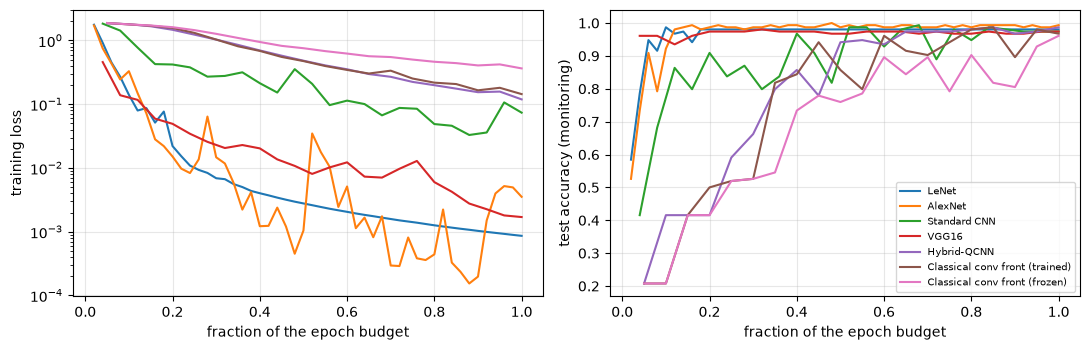

In [14]:
# Learning curves (seed 0): training loss and (monitoring-only) test accuracy per epoch
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for name in MODEL_ORDER + CONTROLS:
    cv = curves[(SEED, name)]
    axes[0].plot(np.arange(1, len(cv) + 1) / len(cv), cv[:, 0], label=name)
    axes[1].plot(np.arange(1, len(cv) + 1) / len(cv), cv[:, 1], label=name)
axes[0].set_ylabel("training loss"); axes[1].set_ylabel("test accuracy (monitoring)")
for a in axes: a.set_xlabel("fraction of the epoch budget"); a.grid(alpha=.3)
axes[0].set_yscale("log"); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

### Figures 4 and 5: confusion matrices of the best classical model and of the Hybrid-QCNN

Rows are the true family, columns the predicted family, for the first split. The paper observes that the Hybrid-QCNN mistakes mostly involve two
families that look like Trusted apps. In Malimg the two look-alike families are Allaple.A and Allaple.L (two variants of the same worm).

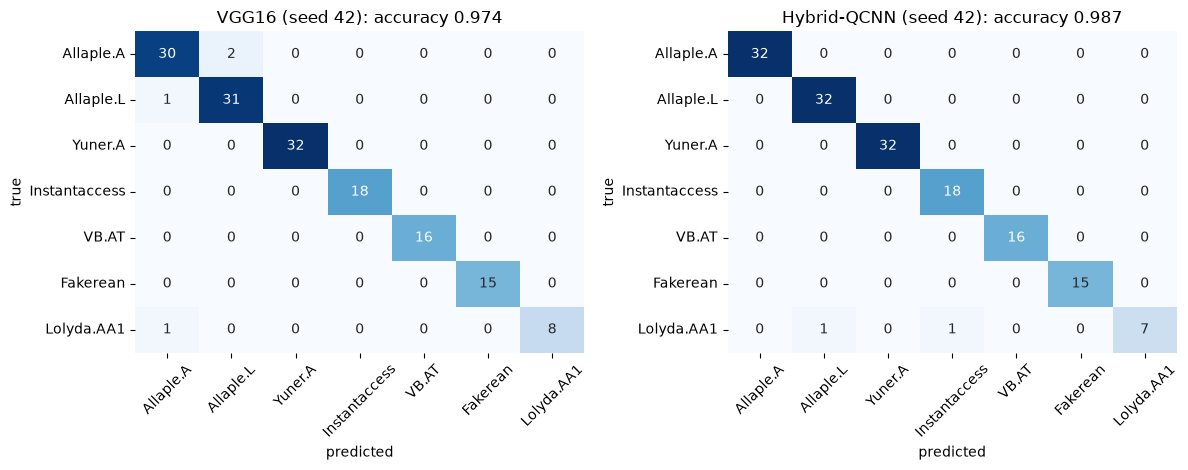

In [15]:
import seaborn as sns
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, name in zip(axes, ["VGG16", "Hybrid-QCNN"]):
    yt, yp = preds[(SEED, name)]
    cm = confusion_matrix(yt, yp, labels=range(N_CLASSES))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=CLASSES, yticklabels=CLASSES)
    ax.set_title(f"{name} (seed {SEED}): accuracy {np.trace(cm) / cm.sum():.3f}"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

### Table 3: per-family precision, recall and F-measure of VGG16 and the Hybrid-QCNN (pooled over all test sets)

In [16]:
from sklearn.metrics import precision_recall_fscore_support
def per_class(name):
    yt = np.concatenate([preds[(SEED + s, name)][0] for s in range(N_SEEDS)]); yp = np.concatenate([preds[(SEED + s, name)][1] for s in range(N_SEEDS)])
    p, r, f, _ = precision_recall_fscore_support(yt, yp, labels=range(N_CLASSES), zero_division=0)
    return pd.DataFrame({"precision": p, "recall": r, "F1": f}, index=CLASSES).round(2)
pc = pd.concat({"VGG16": per_class("VGG16"), "Hybrid-QCNN": per_class("Hybrid-QCNN")}, axis=1)
display(pc)

VGG16              Hybrid-QCNN             
              precision recall    F1   precision recall    F1
Allaple.A          0.91   0.96  0.93        0.98   1.00  0.99
Allaple.L          0.96   0.92  0.94        0.99   0.98  0.98
Yuner.A            1.00   1.00  1.00        0.97   1.00  0.98
Instantaccess      1.00   1.00  1.00        0.98   1.00  0.99
VB.AT              1.00   1.00  1.00        0.98   0.94  0.96
Fakerean           1.00   1.00  1.00        1.00   1.00  1.00
Lolyda.AA1         1.00   0.96  0.98        1.00   0.89  0.94

## 7. Side by side with the paper

Verdict rule (from the project brief): an accuracy within 0.02 of the paper's value, or an F-measure within 0.02, is *reproduced*; otherwise *not reached* (ours is lower)
or *exceeded* (ours is higher), with the gap. Claims that the data cannot test are marked *cannot be checked*. Remember that the data set differs (Section 1), so a "reproduced" verdict
means the number agrees, not that the experiment is the same.

In [17]:
PAPER = {  # Table 2 of the paper: Loss, Accuracy, Precision, Recall, F-measure, AUC
    "LeNet":        dict(Loss=1.86, Accuracy=0.25, Precision=0.00, Recall=0.00, F1=0.00, AUC=0.62),
    "AlexNet":      dict(Loss=1.87, Accuracy=0.25, Precision=0.00, Recall=0.00, F1=0.00, AUC=0.62),
    "Standard CNN": dict(Loss=0.28, Accuracy=0.90, Precision=0.95, Recall=0.84, F1=0.89, AUC=0.99),
    "VGG16":        dict(Loss=0.15, Accuracy=0.95, Precision=0.96, Recall=0.95, F1=0.95, AUC=0.99),
    "Hybrid-QCNN":  dict(Loss=0.81, Accuracy=0.91, Precision=0.92, Recall=0.91, F1=0.91, AUC=0.97),
}
def verdict(ours, paper, tol):
    d = ours - paper
    if abs(d) <= tol: return "reproduced"
    return f"exceeded (+{d:.3f})" if d > 0 else f"not reached ({d:.3f})"

M = lambda m, c: agg.loc[m, (c, "mean")]
recs = []
for m in MODEL_ORDER:
    for c, tol in [("Accuracy", 0.02), ("F1", 0.02)]:
        recs.append(dict(claim=f"{m}: {c}", paper=PAPER[m][c], notebook=round(M(m, c), 3), verdict=verdict(M(m, c), PAPER[m][c], tol)))
for m in ["Standard CNN", "VGG16", "Hybrid-QCNN"]:
    for c in ["Precision", "Recall", "AUC"]:
        recs.append(dict(claim=f"{m}: {c}", paper=PAPER[m][c], notebook=round(M(m, c), 3), verdict=verdict(M(m, c), PAPER[m][c], 0.02)))

acc = {m: M(m, "Accuracy") for m in MODEL_ORDER}
best = max(acc, key=acc.get); second = sorted(acc, key=acc.get)[-2]
recs.append(dict(claim="VGG16 is the most accurate model", paper="VGG16 best (0.95)", notebook=f"best = {best} ({acc[best]:.3f}); VGG16 {acc['VGG16']:.3f}",
                 verdict="reproduced" if acc["VGG16"] >= max(acc.values()) - 1e-9 else ("tie within 1 pt" if acc["VGG16"] >= max(acc.values()) - 0.01 else "not reached")))
recs.append(dict(claim="Hybrid-QCNN is second best, ahead of Standard CNN", paper="0.91 vs 0.90", notebook=f"HQCNN {acc['Hybrid-QCNN']:.3f} vs Std CNN {acc['Standard CNN']:.3f}; 2nd = {second}",
                 verdict="reproduced" if acc["Hybrid-QCNN"] >= acc["Standard CNN"] and acc["Hybrid-QCNN"] >= acc["LeNet"] and acc["Hybrid-QCNN"] >= acc["AlexNet"] else "not reached"))
gap = acc["VGG16"] - acc["Hybrid-QCNN"]
recs.append(dict(claim="25x25 Hybrid-QCNN stays within ~4 points of 100x100x3 VGG16", paper="gap 0.04", notebook=f"gap {gap:.3f}",
                 verdict="reproduced" if gap <= 0.06 else f"not reached (gap {gap:.3f})"))
recs.append(dict(claim="LeNet and AlexNet fail completely (accuracy 0.25, precision = recall = 0)", paper="0.25 / 0 / 0", notebook=f"LeNet {acc['LeNet']:.3f}, AlexNet {acc['AlexNet']:.3f}",
                 verdict="reproduced" if max(acc["LeNet"], acc["AlexNet"]) <= 0.30 else f"not reached (they learn, accuracies {acc['LeNet']:.2f}/{acc['AlexNet']:.2f})"))
ratio = M("Hybrid-QCNN", "time_s") / M("VGG16", "time_s")
recs.append(dict(claim="Hybrid-QCNN training is orders of magnitude slower than VGG16", paper="7:43:21 vs 5:56 (78x)", notebook=f"{M('Hybrid-QCNN','time_s'):.0f} s vs {M('VGG16','time_s'):.0f} s ({ratio:.1f}x)",
                 verdict="reproduced" if ratio >= 20 else f"not reached ({ratio:.1f}x: fixed circuit simulated once)"))
yt_all = np.concatenate([preds[(SEED + s, "Hybrid-QCNN")][0] for s in range(N_SEEDS)]); yp_all = np.concatenate([preds[(SEED + s, "Hybrid-QCNN")][1] for s in range(N_SEEDS)])
wrong = yt_all != yp_all
conf_pair = (wrong & np.isin(yt_all, [0, 1]) & np.isin(yp_all, [0, 1])).sum()
share = conf_pair / max(wrong.sum(), 1)
recs.append(dict(claim="Hybrid-QCNN errors concentrate on two look-alike families", paper="Airpush/Dowgin <-> Trusted (Fig. 5)", notebook=f"{conf_pair} of {wrong.sum()} errors are Allaple.A <-> Allaple.L ({share:.0%})",
                 verdict="reproduced (qualitatively; different families)" if share >= 0.5 else "not reached (errors spread over other families)"))
recs.append(dict(claim="Per-family numbers of Table 3 (Airpush, Dowgin, ..., Trusted)", paper="Table 3", notebook="different families", verdict="cannot be checked"))
recs.append(dict(claim="Absolute accuracy on the authors' 8,446 Android apps", paper="0.91 / 0.95", notebook="data not public", verdict="cannot be checked"))
comparison = pd.DataFrame(recs)
display(comparison)

,claim,paper,notebook,verdict
0,LeNet: Accuracy,0.25,0.994,exceeded (+0.744)
1,LeNet: F1,0.0,0.991,exceeded (+0.991)
2,AlexNet: Accuracy,0.25,0.998,exceeded (+0.748)
3,AlexNet: F1,0.0,0.996,exceeded (+0.996)
4,Standard CNN: Accuracy,0.9,0.989,exceeded (+0.089)
5,Standard CNN: F1,0.89,0.991,exceeded (+0.101)
6,VGG16: Accuracy,0.95,0.972,exceeded (+0.022)
7,VGG16: F1,0.95,0.979,exceeded (+0.029)
8,Hybrid-QCNN: Accuracy,0.91,0.983,exceeded (+0.073)
9,Hybrid-QCNN: F1,0.91,0.978,exceeded (+0.068)


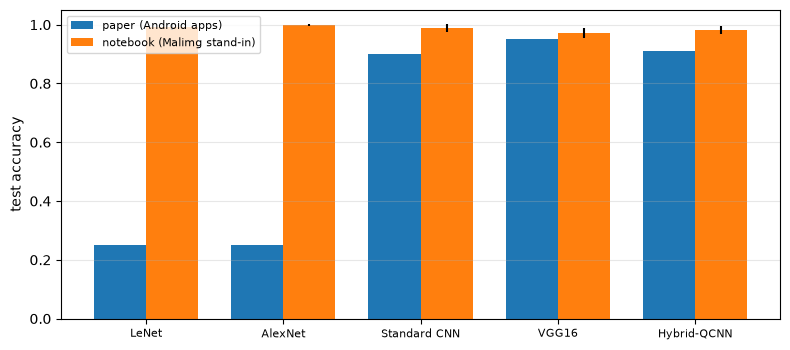

Total notebook run time: 53.2 min (FAST_MODE=False)


In [18]:
# Bar chart: paper vs notebook accuracy
fig, ax = plt.subplots(figsize=(8, 3.6))
xs = np.arange(len(MODEL_ORDER)); w = 0.38
ax.bar(xs - w / 2, [PAPER[m]["Accuracy"] for m in MODEL_ORDER], w, label="paper (Android apps)")
ax.bar(xs + w / 2, [M(m, "Accuracy") for m in MODEL_ORDER], w, yerr=[agg.loc[m, ("Accuracy", "std")] for m in MODEL_ORDER], label="notebook (Malimg stand-in)")
ax.set_xticks(xs); ax.set_xticklabels(MODEL_ORDER, fontsize=8); ax.set_ylabel("test accuracy"); ax.set_ylim(0, 1.05); ax.legend(fontsize=8); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()
print(f"Total notebook run time: {(time.time() - T_NOTEBOOK_START) / 60:.1f} min (FAST_MODE={FAST_MODE})")

## 8. What the controls say about the quantum layer

The paper's argument is that a quantum first layer on a small 25x25 image is competitive with large classical networks. The rows below isolate that layer: same head, same input, same training budget,
different first layer. Differences of one or two accuracy points are inside the noise of a test set this small.

In [19]:
ctrl = results[results.model.isin(["Hybrid-QCNN"] + CONTROLS + BASELINES[:2])].groupby("model")[["Accuracy", "F1", "AUC"]].agg(["mean", "std"]).fillna(0)
display(ctrl.round(3))

Accuracy            F1           AUC       
                                   mean    std   mean    std   mean    std
model                                                                     
Classical conv front (frozen)     0.913  0.061  0.930  0.050  0.994  0.005
Classical conv front (trained)    0.987  0.017  0.989  0.015  0.997  0.005
Hybrid-QCNN                       0.983  0.014  0.978  0.009  1.000  0.000
RandomForest (25x25 px)           0.985  0.015  0.980  0.020  1.000  0.000
SVC-rbf (25x25 px)                0.994  0.006  0.994  0.008  0.999  0.002

## 9. Reading the paper critically

* **No claim of quantum advantage can follow from this design.** The Hybrid-QCNN is compared with models that see 16 times more pixels; no classical network with the *same* 25x25 input and the *same*
  head is reported. The controls above fill that gap: if a frozen or trainable classical 2x2 convolution does as well as the quantum one, the quantum circuit contributes nothing measurable.
* **A fixed random quantum layer is a fixed random nonlinear feature map.** With the circuit frozen, the quantum part is a (costly to simulate) preprocessing step. The 7 h 43 min of the paper come from simulating
  the circuit inside the training loop in TensorFlow Quantum, not from any property of the model; our pre-computed version takes seconds.
* **LeNet and AlexNet scoring 0.25 with precision = recall = 0** looks like failed training (one class predicted for everything, or diverged
  optimisation), not a statement about these architectures; the paper's explanation (too few layers) is not supported by the Standard CNN, which is smaller than VGG16 but works. Properly trained, these small CNNs usually learn this kind of task.
* **Only one run, one split, no confidence interval.** With about 1,700 test images (20 % of 8,446) a difference of 0.04 between VGG16 and the Hybrid-QCNN is about 2 standard errors; the paper reports no repeat.
* **Near-duplicate samples.** Malware families consist of near-identical variants (Malimg's Allaple.A has hundreds of pictures that differ in a few bytes). Random splits then put almost the same image in the
  training and the test set, which inflates every accuracy (including ours). Splitting by app version or by time would be a harder and more honest test; the paper does not discuss this.
* **Image-from-bytes is brittle.** Repacking, resource obfuscation or changing the byte order changes the picture without changing the behaviour; adversarial robustness of such image classifiers is not evaluated.
* **Metric definitions.** The multi-class averaging is not given; the Table 2 recall (0.84) below the precision (0.95) for the Standard CNN, with accuracy 0.90, suggests macro averaging, which is what we used.

## 10. Exercises

1. **Train the quantum layer.** Wrap one `qml.RandomLayers` circuit in `qml.qnn.TorchLayer` (replace the random gates by `qml.StronglyEntanglingLayers`) and train it jointly with the head on 10x10 images (the `NEW_SIZE` of Listing 2). Does a trainable quantum filter beat the frozen one?
2. **Noise.** Replace `default.qubit` by `default.mixed` with `qml.DepolarizingChannel(0.01)` after each layer and recompute `XQ`. How fast does accuracy fall with the noise level?
3. **More data, harder split.** Set `USE_TRAIN_ZIP = True` and `CAP_PER_CLASS = 800`, and use the 25 families. Then group the split by the first characters of the file name (a crude proxy for variant) to reduce near-duplicate leakage.
4. **Fair comparison.** Give VGG16 and the Standard CNN the same 25x25 input as the Hybrid-QCNN (adjusting the dense layer sizes). Is the 100x100 vs 25x25 advantage the paper reports real?
5. **Circuit ablation.** Vary `Q_LAYERS` (1, 2, 8) and `N_Q_CIRCUITS` (1, 4). Which part of the circuit matters, and does the answer change if the circuit is replaced by a single layer of `RY` rotations without entanglement?